In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not on colab')

Mounted at /content/drive


# Movie Recommender System using MovieLens data (Plot embeddings)
Author: Michael Fitiavana Randriamifidy

Created: 27 December 2025

Last Updated: 10 January 2026

In [2]:
import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
DATA_SIZE_DICT= {
    0: "ml-latest-small",
    1: "ml-25m ",
    2: "ml-32m",
}
DATA_SIZE_STR = DATA_SIZE_DICT[2]

# Setting up

In [4]:
import importlib
sys.modules["imp"] = importlib
%load_ext autoreload
%reload_ext autoreload
%autoreload 2

## Setting up Notebooks

In [5]:
!pip install adjustText -q

In [6]:
from typing import Optional, Callable, Dict, Any, List

def download_and_extract_movielens(
                            data_folders:List[str],
                            extracted_data_folder:str='./data',
                            data_size_str:str='ml-latest-small',
                            only_extract:bool=True
                            ):
    pattern = re.compile(rf"{data_size_str}\.zip$")
    for data_folder in data_folders:
        matches = [p for p in Path(data_folder).iterdir() if pattern.match(p.name)]
        if matches:
            print("Found zip file(s):", str(matches[-1]))
            break
    if not  matches:
        print(f"Downloading:{data_size_str}.zip from https://files.grouplens.org/datasets/movielens/{data_size_str}.zip")
        !curl -C - -O --output-dir "{data_folder}" "https://files.grouplens.org/datasets/movielens/{data_size_str}.zip"
    print(f"Extract to {extracted_data_folder}")
    !unzip -n "{data_folder}/{data_size_str}.zip" -d "{extracted_data_folder}"


    pattern = re.compile(rf"{data_size_str}\.zip.md5$")
    for data_folder in data_folders:
        matches = [p for p in Path(data_folder).iterdir() if pattern.match(str(p))]
        if matches:
            print("Found zip.md5 file(s):", str(matches[-1]))
            break
    if not  matches:
        print(f"Downloading:{data_size_str}.zip.md5 from https://files.grouplens.org/datasets/movielens/{data_size_str}.zip.md5")
        !curl -C - -O --output-dir "{data_folder}"  "https://files.grouplens.org/datasets/movielens/{data_size_str}.zip.md5"

def is_kaggle() -> bool:
    """
    Detect if the code is running on Kaggle.

    Returns:
        bool: True if running on Kaggle, False otherwise.
    """
    return "KAGGLE_URL_BASE" in os.environ


def is_colab() -> bool:
    """
    Detect if the code is running on Google Colab.

    Returns:
        bool: True if running on Google Colab, False otherwise.
    """
    try:
        import google.colab
        return True
    except ImportError:
        return False


def set_project(
    fun_todo_kaggle: Optional[Callable[..., Any]] = None,
    fun_todo_colab: Optional[Callable[..., Any]] = None,
    fun_todo_local: Optional[Callable[..., Any]] = None,
    kwargs_kaggle: Optional[Dict[str, Any]] = None,
    kwargs_colab: Optional[Dict[str, Any]] = None,
    kwargs_local: Optional[Dict[str, Any]] = None
) -> Optional[Any]:
    """
    Execute platform-specific setup functions based on the current environment.

    This function detects whether code is running on Kaggle, Google Colab, or locally,
    and executes the corresponding setup function with the provided keyword arguments.

    Args:
        fun_todo_kaggle: Optional function to execute on Kaggle.
        fun_todo_colab: Optional function to execute on Google Colab.
        fun_todo_local: Optional function to execute locally.
        kwargs_kaggle: Keyword arguments to pass to the Kaggle function.
        kwargs_colab: Keyword arguments to pass to the Colab function.
        kwargs_local: Keyword arguments to pass to the local function.

    Returns:
        The return value of the executed function, or None if no function is provided
        for the detected environment.
    """
    # Initialize kwargs dictionaries if None
    kwargs_kaggle = kwargs_kaggle or {}
    kwargs_colab = kwargs_colab or {}
    kwargs_local = kwargs_local or {}

    # Conditional commands
    if is_kaggle():
        print("Running on Kaggle")
        if fun_todo_kaggle is not None:
            return fun_todo_kaggle(**kwargs_kaggle)
    elif is_colab():
        print("Running on Google Colab")
        if fun_todo_colab is not None:
            return fun_todo_colab(**kwargs_colab)
    else:
        print("Running locally")
        if fun_todo_local is not None:
            return fun_todo_local(**kwargs_local)

    return None

def is_drive_mounted():
    return os.path.exists("/content/drive/MyDrive")


def fun_todo_kaggle(**kwargs):
    data_size_str = kwargs['data_size_str'] if "data_size_str" in kwargs else "latest-small"
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    # os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(f"/kaggle/working/movie-recommender-system-{data_size_str}")
    PROJECT_PATH = Path("/kaggle/temp/")
    DATA_FOLDER = PROJECT_PATH / "download/data"
    EXTRACTED_DATA_FOLDER = Path("/kaggle/input/movielens-dataset/")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20
    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER

def fun_todo_colab(**kwargs):
    if is_drive_mounted():
        print("Google Drive is already mounted")
    else:
        raise "Mount Drive"

    data_size_str = kwargs['data_size_str'] if "data_size_str" in kwargs else "latest-small"
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    # os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(project_dir_abs) / f"working/movie-recommender-system-{data_size_str}"
    PROJECT_PATH =  Path(project_dir_abs) / f"temp/movie-recommender-system-{data_size_str}"
    DATA_FOLDER = Path("./downloads/data")
    EXTRACTED_DATA_FOLDER = Path("./data")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20

    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)
    download_and_extract_movielens(
        [DATA_FOLDER, project_dir_abs / DATA_FOLDER],
        EXTRACTED_DATA_FOLDER,
        data_size_str = DATA_SIZE_STR)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER

def fun_todo_local(**kwargs):
    data_size_str = kwargs.get('data_size_str', 'latest-small')
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(project_dir_abs) / f"working/movie-recommender-system-{data_size_str}"
    PROJECT_PATH =  Path(project_dir_abs) / f"temp/movie-recommender-system-{data_size_str}"
    DATA_FOLDER = Path("./downloads/data")
    EXTRACTED_DATA_FOLDER = Path("./data")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20
    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)

    download_and_extract_movielens(
        [DATA_FOLDER, project_dir_abs / DATA_FOLDER],
        EXTRACTED_DATA_FOLDER,
        data_size_str = DATA_SIZE_STR)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER


In [7]:
if Path.cwd().name == "notebooks":
    PROJECT_DIR_ABS = Path.cwd().parent
else:
    PROJECT_DIR_ABS = Path.cwd()
print(f"MovieLens data:{DATA_SIZE_STR}")
kwargs = {"data_size_str":DATA_SIZE_STR}
kwargs_kaggle = {**kwargs, **{'project_dir_abs':Path(f"/kaggle/input/movie-recommender-system-{DATA_SIZE_STR}")}}
kwargs_colab = {**kwargs, **{'project_dir_abs':Path(f"/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system")},}
kwargs_local = {**kwargs, **{'project_dir_abs':PROJECT_DIR_ABS}}
(
    REMOTE_PROJECT_PATH,
    PROJECT_PATH,
    DATA_FOLDER,
    EXTRACTED_DATA_FOLDER
    ) = set_project(fun_todo_kaggle,
                    fun_todo_colab,
                    fun_todo_local,
                    kwargs_kaggle=kwargs_kaggle,
                    kwargs_colab=kwargs_colab,
                    kwargs_local=kwargs_local)

ratings_path = EXTRACTED_DATA_FOLDER / DATA_SIZE_STR / "ratings.csv"
movies_path = EXTRACTED_DATA_FOLDER / DATA_SIZE_STR / "movies.csv"
PLOT_FOLDER = PROJECT_PATH / "plots"
MODEL_FOLDER = PROJECT_PATH / "models"
REMOTE_MODEL_FOLDER = REMOTE_PROJECT_PATH / "models"

MovieLens data:ml-32m
Running on Google Colab
Google Drive is already mounted
/content
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m:
models

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m/models:
with_embeddings
with_features

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m/models/with_embeddings:
ml-32m-als-K02-best_nepochs14-maxiter50-lambda1-tau0.1-with_embeddings-latest.joblib
ml-32m-als-K02-best_nepochs21-maxiter50-lambda1-tau10-with_embeddings-latest.joblib
ml-32m-als-K02-best_nepochs23-maxiter50-lambda1-tau1-with_embeddings-latest.joblib
ml-32m-als-K04-best_nepochs15-maxiter50-lambda1-tau10-with_embeddings-latest.joblib
ml-32m-als-K04-best_nepochs22-maxiter50-lambda1-tau0.1-with_embeddings-latest.joblib
ml-32m-als-K04-best_nepochs23-maxiter50-lambda1-tau1-with_embeddings-latest.joblib
ml-32m-als-K08-best_nepochs12-m

In [8]:
PLOT_FOLDER = PLOT_FOLDER / "embeddings_and_polarization"

## Import

In [9]:
from recommender.utils.helpers import (
    set_project,
    get_indices,
    sort_array
    )

from recommender.data.csr import (
    get_nrows_csr,
    get_rows_from_csr
)

from recommender.data.stats import (
    get_outliers_iqr
)
from recommender.data.ratings import (
    get_id_from_idx,
    get_idx_from_id,
    load_data_movie_feature_csr,
    load_movie_id_idx_mapping,
    load_ratings_and_features_data_csr,
    get_movie_title_from_id,
    get_movies_by_features,
    get_rating_distribution_for_items
)
from recommender.models.model_io import (
    load_models_filtered,
    add_suffix_model_info
)

from recommender.plots.plotting import (
    plot_als_curves_multiple_models,
    plot_2dvectors,
    plot_multiple_box_general,
    plot_distribution_general,
    save_plot
)
from recommender.models.train import (
    get_top_long_trait_vector
)

from recommender.data.dimension_reduction import (
    compute_umap_reducer
)

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/recommender/utils/helpers.py:402: SyntaxWarning: invalid escape sequence '\.'
  Default is '.*' (all files). Example: r".*\.txt$" or [r".*\.txt$", r".*\.py$"].


# Load movie datasets

In [10]:
(
    user_id_to_idx, user_idx_to_id, movie_id_to_idx, movie_idx_to_id,
    feature_idx_to_id, feature_id_to_idx,
    ratings_by_user_csr, ratings_by_movie_csr,
    features_by_movie_csr, movies_by_feature_csr, movies_title
)= load_ratings_and_features_data_csr(ratings_path, movies_path)
assert get_nrows_csr(ratings_by_user_csr) == get_nrows_csr(ratings_by_user_csr)

Loading ratings:   0%|          | 0/32000204 [00:00<?, ? lines/s]

Loading features:   0%|          | 0/87585 [00:00<?, ? lines/s]

In [11]:
(
    data_movie_id_to_idx,
    data_movie_idx_to_id,
    data_feature_id_to_idx,
    data_feature_idx_to_id,
    data_movies_title,
    data_movies_by_feature_csr,
    data_features_by_movie_csr,
    ) = load_data_movie_feature_csr(movies_path)

movie_id_to_idx, movie_idx_to_id = load_movie_id_idx_mapping(ratings_path)

Loading movies'feature:   0%|          | 0/87585 [00:00<?, ? movie/s]

Loading rated movie Id:   0%|          | 0/32000204 [00:00<?, ? ratings/s]

# Features to Study

In [196]:
feature_ids = ['Children', 'Horror']

feature_ids = ['Children', 'Horror', 'War']

# Plot embeddings K=2: Model trained with Embeddings

### Load Model

In [197]:
K_list = [2]
vector_penality= 10
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[1]
models_folder =  Path(REMOTE_MODEL_FOLDER) / mode
pattern = r"latest.joblib$"
models =  load_models_filtered(models_folder, K_list= K_list,vector_penality_list = [vector_penality],  pattern=pattern)

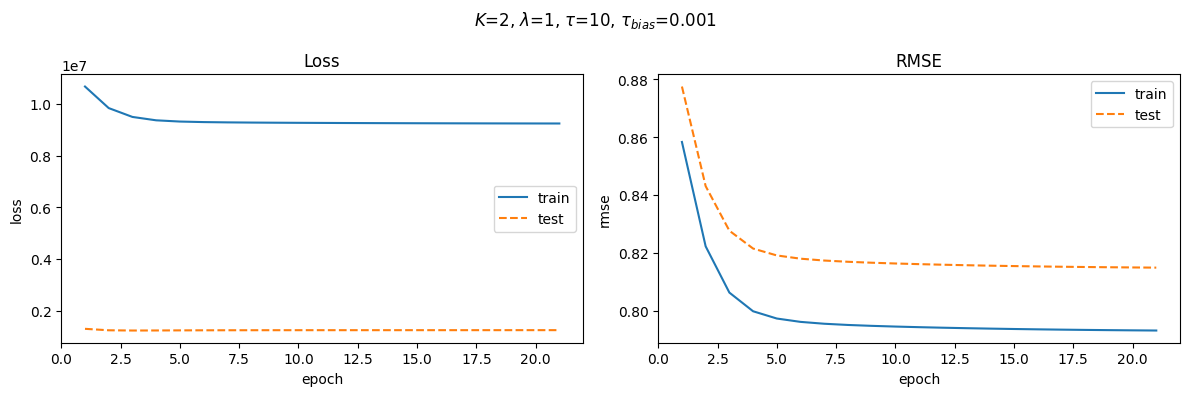

In [198]:
plot_als_curves_multiple_models(models)

In [199]:
fitted_model = models[-1]

## Polarizing Movies

In [200]:
item_vectors = fitted_model.get('item_vectors')

atleast_nratings = 100
nratings_by_item = fitted_model.get('nratings_by_item')
mask = nratings_by_item >= atleast_nratings
indices_atleast_nratings = np.arange(len(mask))[mask]

In [201]:
items_vectors_norm, _ = get_top_long_trait_vector(
    item_vectors,
    sort_flag=False,
    topn=None
)

In [202]:
items_vectors_norms_atleast_nratings = items_vectors_norm[indices_atleast_nratings]

In [203]:
lower_outliers, indices_lower, upper_outliers, indices_upper = get_outliers_iqr(items_vectors_norms_atleast_nratings)
indices_atleast_nratings_upper = indices_atleast_nratings[indices_upper]

### Most Plolarizing Movies

In [204]:
long_trait_vector, sort_indices = sort_array(upper_outliers)
long_trait_vector_indices = indices_atleast_nratings_upper[sort_indices]
long_trait_vector_ids = get_id_from_idx(long_trait_vector_indices, movie_idx_to_id)
bins, counts_for_each_items = get_rating_distribution_for_items(
    ratings_by_movie_csr,
    long_trait_vector_ids,
    movie_id_to_idx,
    bin_width=0.5
)
_, long_trait_vector_ratings =  get_rows_from_csr(ratings_by_movie_csr, list(long_trait_vector_indices))

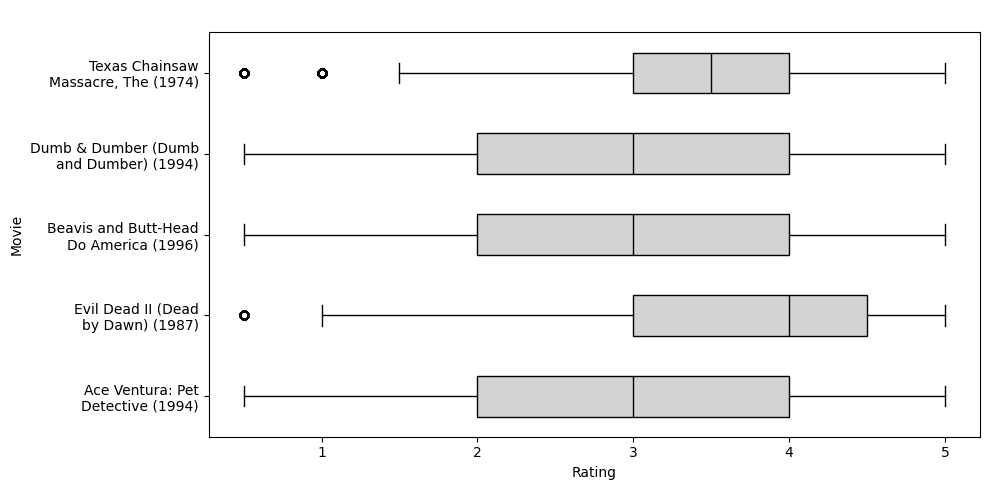

In [205]:
topn = 5
long_traits_titles = get_movie_title_from_id(long_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)

plot_folder = PLOT_FOLDER
filename = f"plot_top-long-trait-boxplot-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if long_trait_vector_ratings:

    title = "Top Movie with Long Traits vectors box-plot Rating Distribution"
    title = " "
    fig, ax = plot_multiple_box_general(
        x_labels=long_traits_titles,
        y_values=long_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Movie",
        ylabel="Rating",
        title=title,
        horizontal=True,
        rotate_xticks=30,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

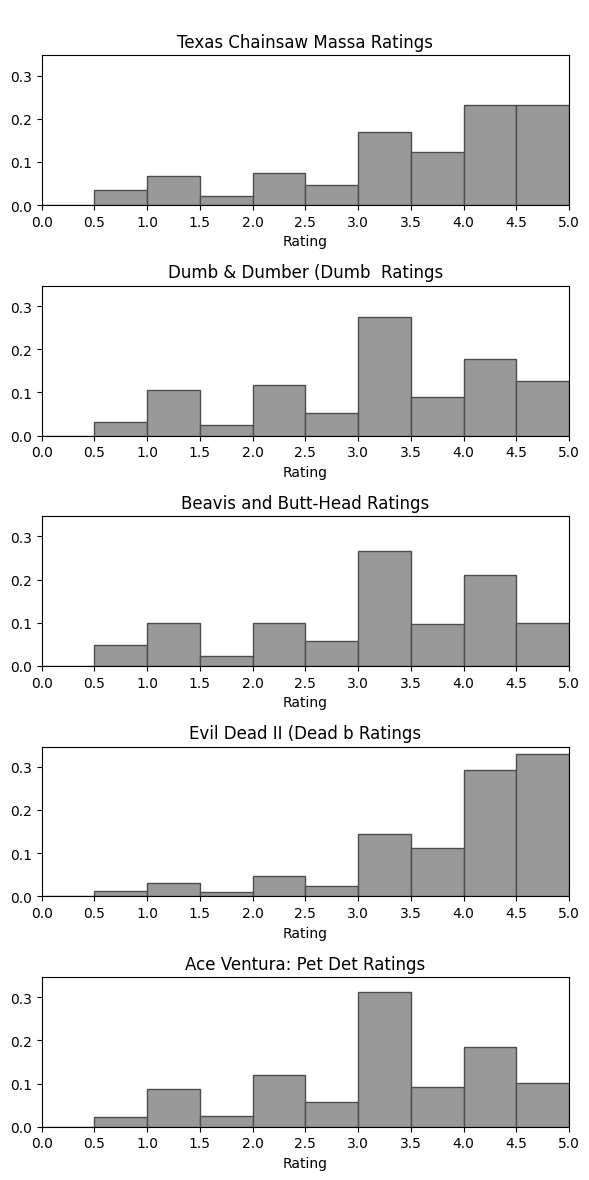

In [206]:
topn = 5
long_traits_titles = get_movie_title_from_id(long_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)
plot_folder = PLOT_FOLDER

K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_top-short-trait-rating-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if long_trait_vector_ratings:
    title = "Top Movie with Short Traits vectors Rating Distribution"
    title = " "

    plot_distribution_general(
        x_labels=long_traits_titles,
        y_values=long_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Rating",
        ylabel="Density",
        title=title,
        horizontal=False,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

In [207]:
ids = long_trait_vector_ids[:1]
indices = get_idx_from_id(ids, movie_id_to_idx)

### Least Plolarizing Movies

In [208]:
atleast_nratings = 100
nratings_by_item = fitted_model.get('nratings_by_item')
mask = nratings_by_item >= atleast_nratings
indices_atleast_nratings = np.arange(len(mask))[mask]

In [209]:
items_vectors_norm, _ = get_top_long_trait_vector(
    item_vectors,
    sort_flag=False,
    topn=None
)

In [210]:
items_vectors_norms_atleast_nratings = items_vectors_norm[indices_atleast_nratings]
lower_outliers, indices_lower, upper_outliers, indices_upper = get_outliers_iqr(items_vectors_norms_atleast_nratings)

indices_atleast_nratings_upper = indices_atleast_nratings[indices_lower]
short_trait_vector, sort_indices = sort_array(lower_outliers, descending=False)
short_trait_vector_indices = indices_atleast_nratings_upper[sort_indices]
short_trait_vector_ids = get_id_from_idx(short_trait_vector_indices, movie_idx_to_id)

bins, counts_for_each_items = get_rating_distribution_for_items(
    ratings_by_movie_csr,
    short_trait_vector_ids,
    movie_id_to_idx,
    bin_width=0.5
)
_, short_trait_vector_ratings =  get_rows_from_csr(ratings_by_movie_csr, list(short_trait_vector_indices))

In [211]:
topn = 5
short_traits_titles = get_movie_title_from_id(short_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)

plot_folder = PLOT_FOLDER
filename = f"plot_top-long-trait-boxplot-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if short_trait_vector_ratings:

    title = "Top Movie with short Traits vectors box-plot Rating Distribution"
    title = " "
    fig, ax = plot_multiple_box_general(
        x_labels=short_traits_titles,
        y_values=short_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Movie",
        ylabel="Rating",
        title=title,
        horizontal=True,
        rotate_xticks=30,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

In [212]:
topn = 5
short_traits_titles = get_movie_title_from_id(short_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)
plot_folder = PLOT_FOLDER

K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_top-short-trait-rating-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if short_trait_vector_ratings:
    title = "Top Movie with Short Traits vectors Rating Distribution"
    title = " "

    plot_distribution_general(
        x_labels=short_traits_titles,
        y_values=short_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Rating",
        ylabel="Density",
        title=title,
        horizontal=False,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

## Movies

In [213]:
item_vectors = fitted_model.get('item_vectors')
sample_size_each = 10**3
(
    item_vectors_subset,
    movie_ids_subset,
    feature_assignments
) = get_movies_by_features(
        feature_ids,
        feature_id_to_idx,
        movies_by_feature_csr,
        item_vectors,
        movie_idx_to_id,
        mode="xor",
        sample_size_each=sample_size_each)


['/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/embeddings_and_polarization/Children_Horror_War/plot_movie_embeddings_by_feature-K02-best_nepochs21-maxiter50-lambda1-tau10-with_embeddings.pdf']

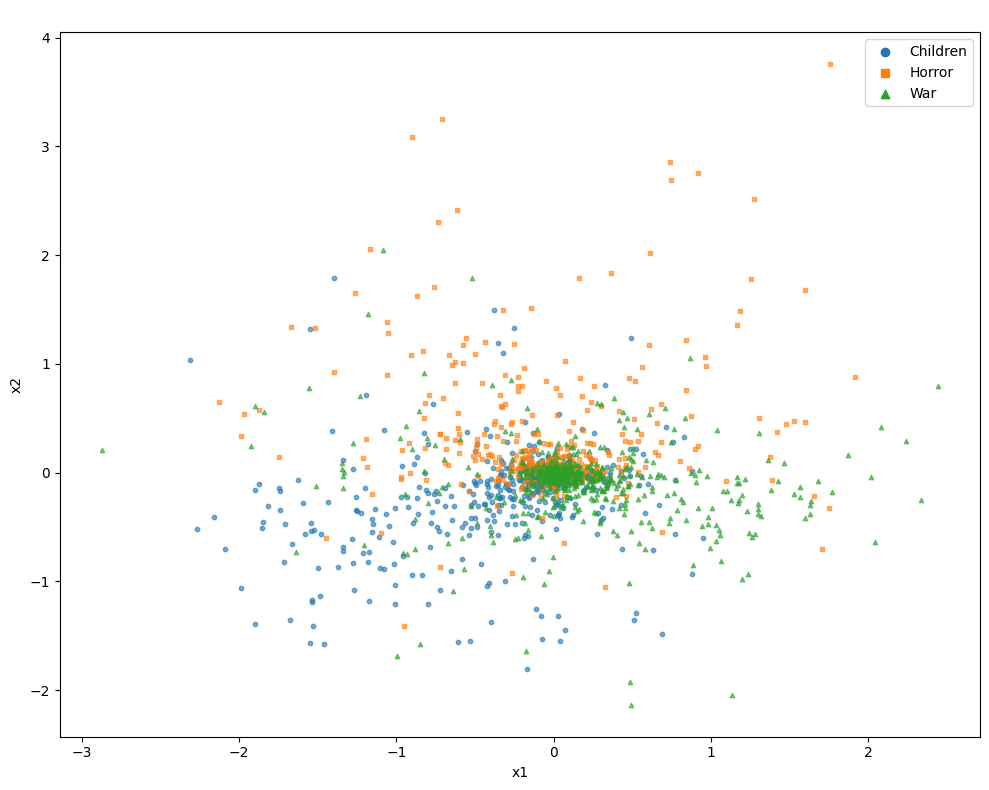

In [214]:
show_labels = False
s = 10

plot_folder = PLOT_FOLDER / '_'.join(feature_ids)
K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_movie_embeddings_by_feature.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

title=rf"Movies by Feature K={K:02d}, $\lambda$={precision}=$\tau$={vector_penality}, iter={max_iter} ({mode})"
x_label="x1"
y_label="x2"

title = " "

fig, ax = plot_2dvectors(
    embedding=item_vectors_subset,
    cluster_labels=feature_assignments,
    cluster_ids=feature_ids,
    point_ids=movie_ids_subset,
    labels=get_movie_title_from_id(
        movie_ids_subset,
        movie_id_to_idx,
        data_movies_title
    ),
    show_labels=show_labels,
    label_fontsize=7,
    cluster_label_fontsize=12,
    s=s,
    alpha=0.6,
    title=title,
    x_label=x_label,
    y_label=y_label
)

save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)


# Plot embeddings K=2: Model trained with features

## Load Model

In [215]:
K_list = [2]
vector_penality= 1
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[2]
models_folder =  Path(REMOTE_MODEL_FOLDER) / mode
pattern = "latest.joblib$"
models =  load_models_filtered(models_folder, K_list= K_list,vector_penality_list = [vector_penality],  pattern=pattern)

## Polarizing Movies

In [216]:
item_vectors = fitted_model.get('item_vectors')

atleast_nratings = 100
nratings_by_item = fitted_model.get('nratings_by_item')
mask = nratings_by_item >= atleast_nratings
indices_atleast_nratings = np.arange(len(mask))[mask]

In [217]:
items_vectors_norm, _ = get_top_long_trait_vector(
    item_vectors,
    sort_flag=False,
    topn=None
)

In [218]:
items_vectors_norms_atleast_nratings = items_vectors_norm[indices_atleast_nratings]

In [219]:
lower_outliers, indices_lower, upper_outliers, indices_upper = get_outliers_iqr(items_vectors_norms_atleast_nratings)
indices_atleast_nratings_upper = indices_atleast_nratings[indices_upper]

### Most Plolarizing Movies

In [220]:
long_trait_vector, sort_indices = sort_array(upper_outliers)
long_trait_vector_indices = indices_atleast_nratings_upper[sort_indices]
long_trait_vector_ids = get_id_from_idx(long_trait_vector_indices, movie_idx_to_id)
bins, counts_for_each_items = get_rating_distribution_for_items(
    ratings_by_movie_csr,
    long_trait_vector_ids,
    movie_id_to_idx,
    bin_width=0.5
)
_, long_trait_vector_ratings =  get_rows_from_csr(ratings_by_movie_csr, list(long_trait_vector_indices))

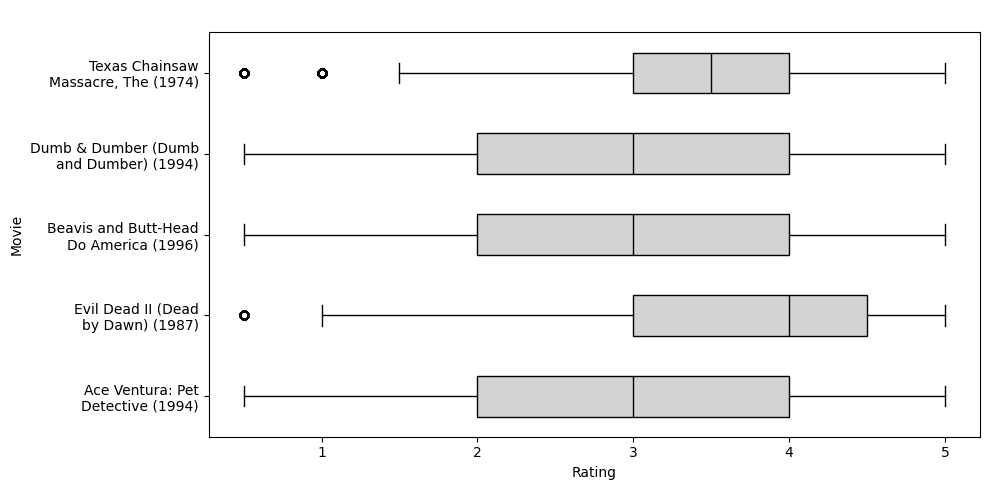

In [221]:
topn = 5
long_traits_titles = get_movie_title_from_id(long_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)

plot_folder = PLOT_FOLDER
filename = f"plot_top-long-trait-boxplot-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if long_trait_vector_ratings:

    title = "Top Movie with Long Traits vectors box-plot Rating Distribution"
    title = " "
    fig, ax = plot_multiple_box_general(
        x_labels=long_traits_titles,
        y_values=long_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Movie",
        ylabel="Rating",
        title=title,
        horizontal=True,
        rotate_xticks=30,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

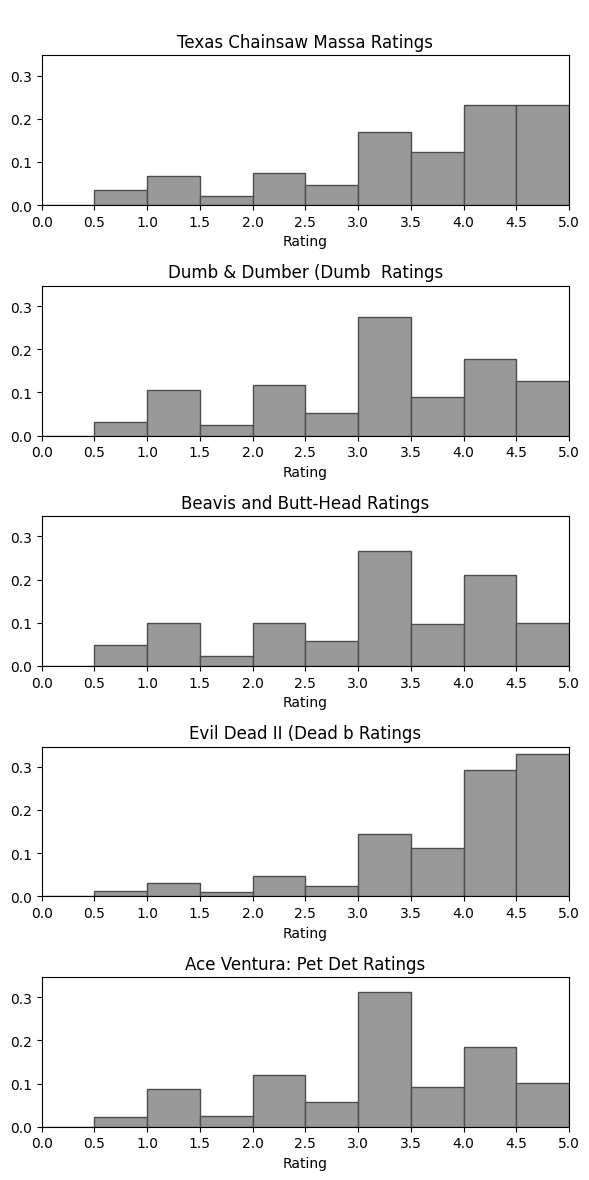

In [222]:
topn = 5
long_traits_titles = get_movie_title_from_id(long_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)
plot_folder = PLOT_FOLDER

K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_top-short-trait-rating-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if long_trait_vector_ratings:
    title = "Top Movie with Short Traits vectors Rating Distribution"
    title = " "

    plot_distribution_general(
        x_labels=long_traits_titles,
        y_values=long_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Rating",
        ylabel="Density",
        title=title,
        horizontal=False,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

In [223]:
ids = long_trait_vector_ids[:1]
indices = get_idx_from_id(ids, movie_id_to_idx)

### Least Plolarizing Movies

In [224]:
atleast_nratings = 100
nratings_by_item = fitted_model.get('nratings_by_item')
mask = nratings_by_item >= atleast_nratings
indices_atleast_nratings = np.arange(len(mask))[mask]

In [225]:
items_vectors_norm, _ = get_top_long_trait_vector(
    item_vectors,
    sort_flag=False,
    topn=None
)

In [226]:
items_vectors_norms_atleast_nratings = items_vectors_norm[indices_atleast_nratings]
lower_outliers, indices_lower, upper_outliers, indices_upper = get_outliers_iqr(items_vectors_norms_atleast_nratings)

indices_atleast_nratings_upper = indices_atleast_nratings[indices_lower]
short_trait_vector, sort_indices = sort_array(lower_outliers, descending=False)
short_trait_vector_indices = indices_atleast_nratings_upper[sort_indices]
short_trait_vector_ids = get_id_from_idx(short_trait_vector_indices, movie_idx_to_id)

bins, counts_for_each_items = get_rating_distribution_for_items(
    ratings_by_movie_csr,
    short_trait_vector_ids,
    movie_id_to_idx,
    bin_width=0.5
)
_, short_trait_vector_ratings =  get_rows_from_csr(ratings_by_movie_csr, list(short_trait_vector_indices))

In [227]:
topn = 5
short_traits_titles = get_movie_title_from_id(short_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)

plot_folder = PLOT_FOLDER
filename = f"plot_top-short-trait-boxplot-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if short_trait_vector_ratings:

    title = "Top Movie with short Traits vectors box-plot Rating Distribution"
    title = " "
    fig, ax = plot_multiple_box_general(
        x_labels=short_traits_titles,
        y_values=short_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Movie",
        ylabel="Rating",
        title=title,
        horizontal=True,
        rotate_xticks=30,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

In [228]:
topn = 5
short_traits_titles = get_movie_title_from_id(short_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)
plot_folder = PLOT_FOLDER

K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_top-short-trait-rating-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if short_trait_vector_ratings:
    title = "Top Movie with Short Traits vectors Rating Distribution"
    title = " "

    plot_distribution_general(
        x_labels=short_traits_titles,
        y_values=short_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Rating",
        ylabel="Density",
        title=title,
        horizontal=False,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

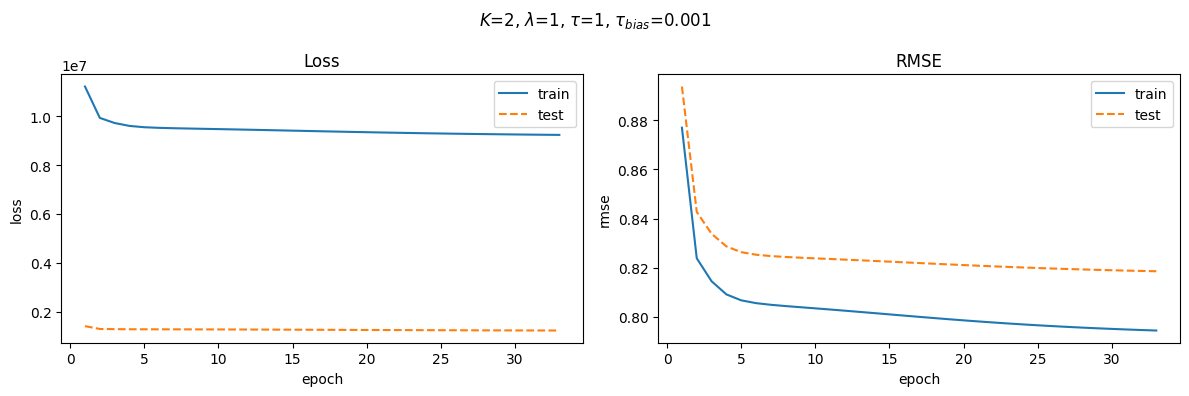

In [229]:
plot_als_curves_multiple_models(models)

In [230]:
fitted_model = models[-1]

## Movies

In [231]:
item_vectors = fitted_model.get('item_vectors')
feature_vectors = fitted_model.get('feature_vectors')
feature_vectors_subset = feature_vectors[get_indices(feature_ids, fitted_model.get('features_ids'))]
sample_size_each = 10**3
(
    item_vectors_subset,
    movie_ids_subset,
    feature_assignments
) = get_movies_by_features(
        feature_ids,
        feature_id_to_idx,
        movies_by_feature_csr,
        item_vectors,
        movie_idx_to_id,
        feature_vectors_subset,
        mode="xor",
        sample_size_each=sample_size_each)


['/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/embeddings_and_polarization/Children_Horror_War/plot_movie_embeddings_by_feature-K02-best_nepochs33-maxiter50-lambda1-tau1-with_features.pdf']

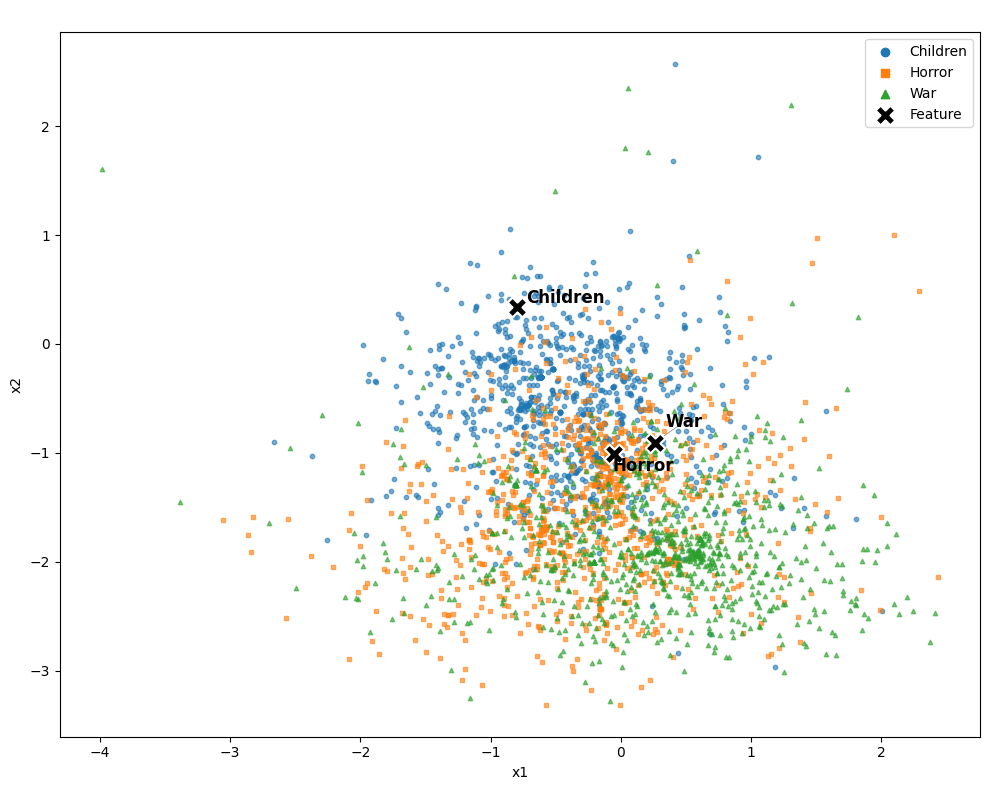

In [232]:
show_labels = False
plot_feature_embeddings = True
s = 10

plot_folder = PLOT_FOLDER / '_'.join(feature_ids)
K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_movie_embeddings_by_feature.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

title=rf"Movies by Feature K={K:02d}, $\lambda$={precision}=$\tau$={vector_penality}, iter={max_iter} ({mode})"
x_label="x1"
y_label="x2"

title = " "

fig, ax = plot_2dvectors(
    embedding=item_vectors_subset,
    cluster_labels=feature_assignments,
    cluster_ids=feature_ids,
    point_ids=movie_ids_subset,
    labels=get_movie_title_from_id(
        movie_ids_subset,
        movie_id_to_idx,
        data_movies_title
    ),
    cluster_embeddings=feature_vectors_subset,
    plot_cluster_embeddings=plot_feature_embeddings,
    show_labels=show_labels,
    label_fontsize=7,
    cluster_label_fontsize=12,
    s=s,
    alpha=0.6,
    title=title,
    x_label=x_label,
    y_label=y_label
)

save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

## Features

In [233]:
feature_vectors = fitted_model['feature_vectors']
reducer_feature = compute_umap_reducer(feature_vectors, n_components=2)
all_features_umap = reducer_feature.embedding_

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


['/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/embeddings_and_polarization/plot_feature_embeddings_by_feature-K02-best_nepochs33-maxiter50-lambda1-tau1-with_features.pdf']

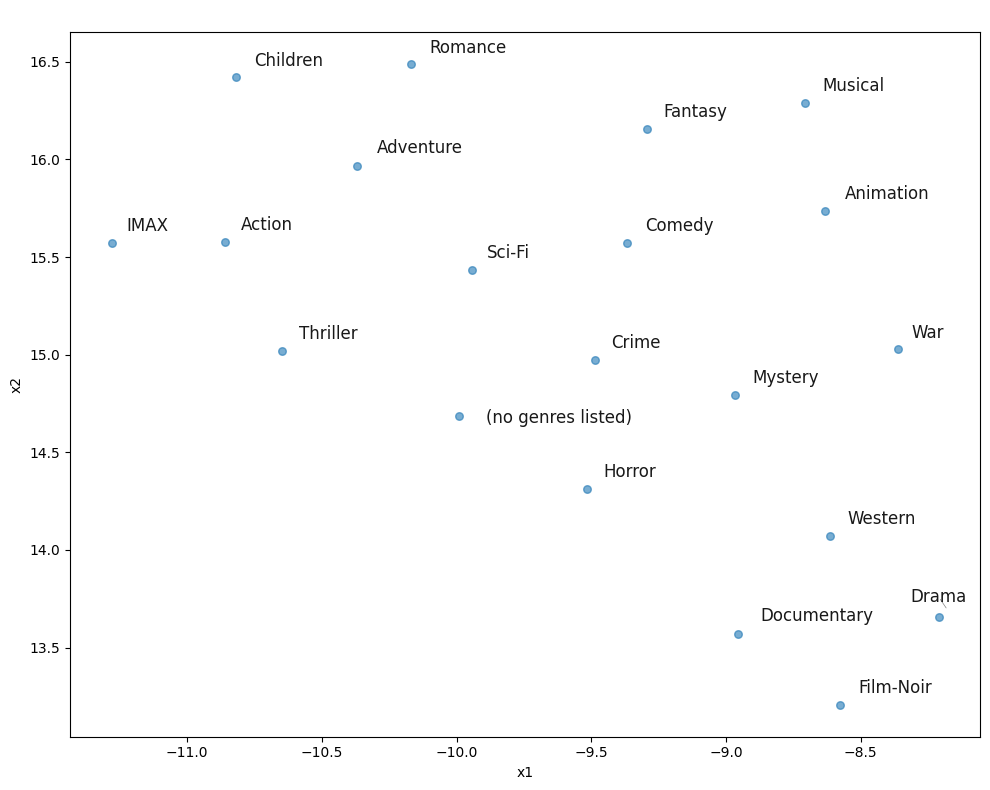

In [234]:
plot_folder = PLOT_FOLDER
K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_feature_embeddings_by_feature.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

title=rf"Features K={K:02d}, $\lambda$={precision}=$\tau$={vector_penality}, iter={max_iter} ({mode})"
x_label="x1"
y_label="x2"

title = " "

fig, ax = plot_2dvectors(
    embedding=all_features_umap,
    cluster_labels=None,
    point_ids= fitted_model['features_ids'],
    show_labels=True,
    label_fontsize=12,
    label_alpha=0.9,
    title=title,
    x_label=x_label,
    y_label=y_label
)

save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

# Plot embeddings K>2: Model trained with Embeddings

### Load Model

In [235]:
K_list = [16]
vector_penality = 10
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[1]
models_folder =  Path(REMOTE_MODEL_FOLDER) / mode
pattern = "latest.joblib$"
models =  load_models_filtered(models_folder, K_list= K_list,vector_penality_list = [vector_penality],  pattern=pattern)

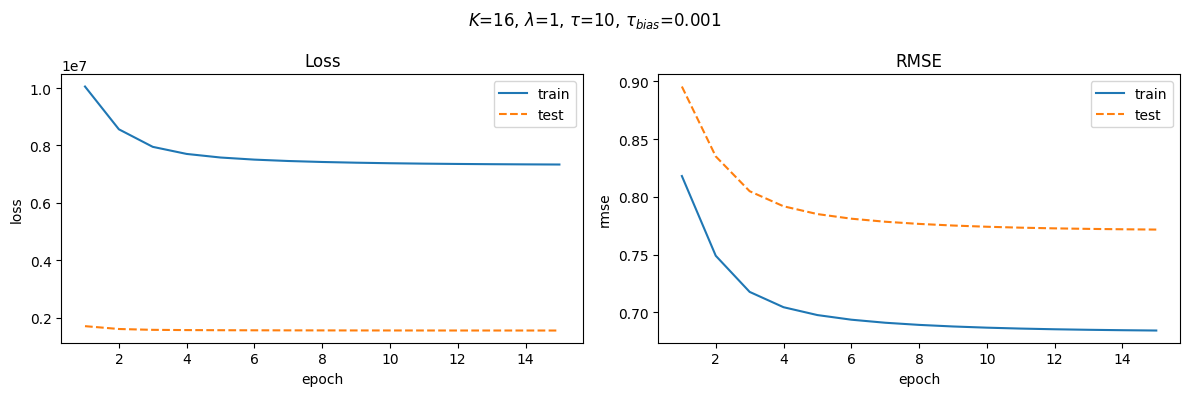

In [236]:
plot_als_curves_multiple_models(models)

In [237]:
fitted_model = models[-1]

## Polarizing Movies

In [238]:
item_vectors = fitted_model.get('item_vectors')

atleast_nratings = 100
nratings_by_item = fitted_model.get('nratings_by_item')
mask = nratings_by_item >= atleast_nratings
indices_atleast_nratings = np.arange(len(mask))[mask]

In [239]:
items_vectors_norm, _ = get_top_long_trait_vector(
    item_vectors,
    sort_flag=False,
    topn=None
)
items_vectors_norms_atleast_nratings = items_vectors_norm[indices_atleast_nratings]
lower_outliers, indices_lower, upper_outliers, indices_upper = get_outliers_iqr(items_vectors_norms_atleast_nratings)
indices_atleast_nratings_upper = indices_atleast_nratings[indices_upper]

### Most Plolarizing Movies

In [240]:
long_trait_vector, sort_indices = sort_array(upper_outliers)
long_trait_vector_indices = indices_atleast_nratings_upper[sort_indices]
long_trait_vector_ids = get_id_from_idx(long_trait_vector_indices, movie_idx_to_id)
bins, counts_for_each_items = get_rating_distribution_for_items(
    ratings_by_movie_csr,
    long_trait_vector_ids,
    movie_id_to_idx,
    bin_width=0.5
)
_, long_trait_vector_ratings =  get_rows_from_csr(ratings_by_movie_csr, list(long_trait_vector_indices))

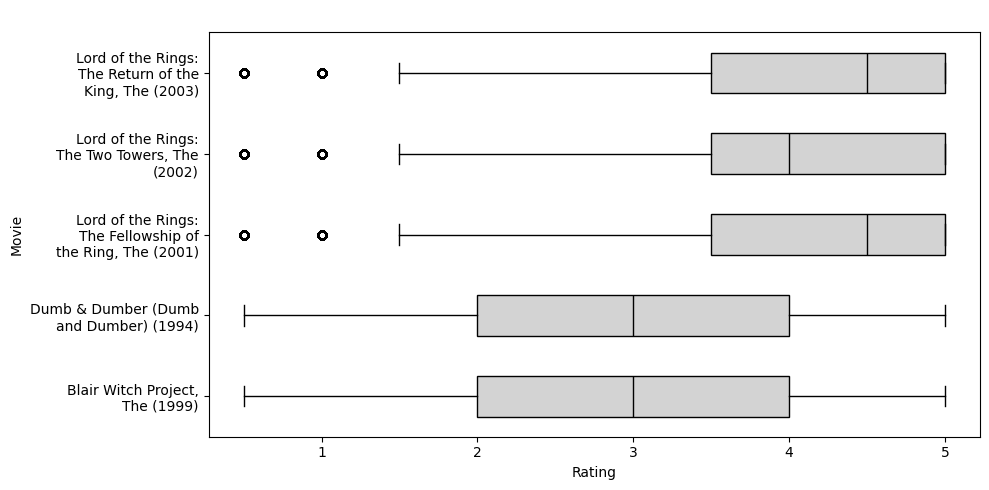

In [241]:
topn = 5
long_traits_titles = get_movie_title_from_id(long_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)

plot_folder = PLOT_FOLDER
filename = f"plot_top-long-trait-boxplot-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if long_trait_vector_ratings:

    title = "Top Movie with Long Traits vectors box-plot Rating Distribution"
    title = " "
    fig, ax = plot_multiple_box_general(
        x_labels=long_traits_titles,
        y_values=long_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Movie",
        ylabel="Rating",
        title=title,
        horizontal=True,
        rotate_xticks=30,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

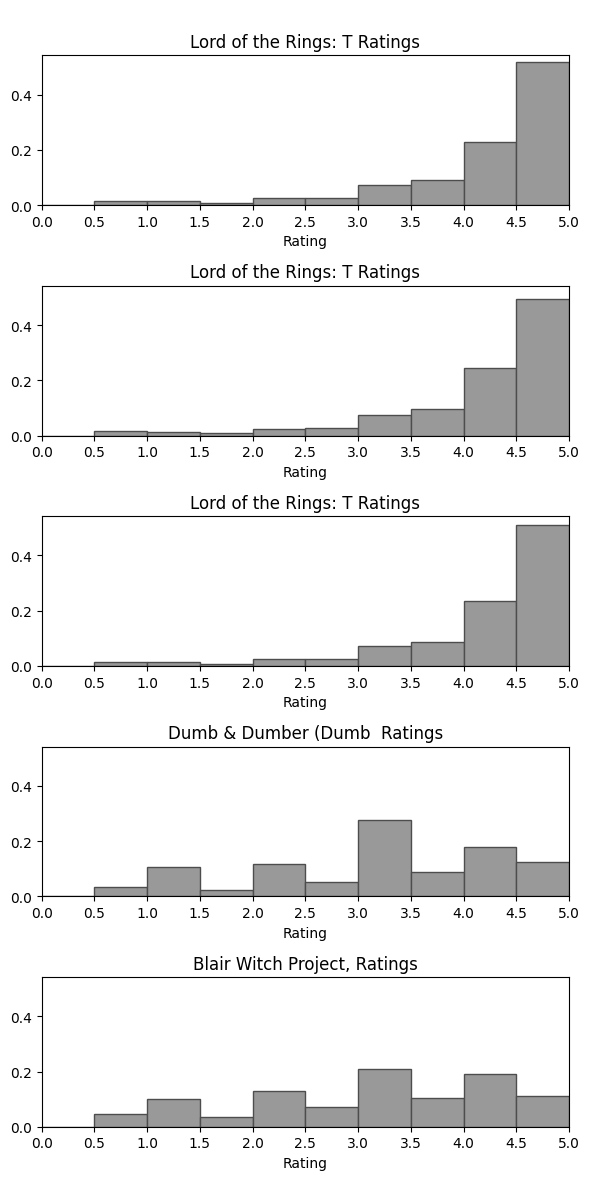

In [242]:
topn = 5
long_traits_titles = get_movie_title_from_id(long_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)
plot_folder = PLOT_FOLDER

K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_top-short-trait-rating-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if long_trait_vector_ratings:
    title = "Top Movie with Short Traits vectors Rating Distribution"
    title = " "

    plot_distribution_general(
        x_labels=long_traits_titles,
        y_values=long_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Rating",
        ylabel="Density",
        title=title,
        horizontal=False,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

### Least Plolarizing Movies

In [243]:
indices_atleast_nratings_upper = indices_atleast_nratings[indices_lower]
short_trait_vector, sort_indices = sort_array(lower_outliers, descending=False)
short_trait_vector_indices = indices_atleast_nratings_upper[sort_indices]
short_trait_vector_ids = get_id_from_idx(short_trait_vector_indices, movie_idx_to_id)

bins, counts_for_each_items = get_rating_distribution_for_items(
    ratings_by_movie_csr,
    short_trait_vector_ids,
    movie_id_to_idx,
    bin_width=0.5
)
_, short_trait_vector_ratings =  get_rows_from_csr(ratings_by_movie_csr, list(short_trait_vector_indices))

In [244]:
topn = 5
short_traits_titles = get_movie_title_from_id(short_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)

plot_folder = PLOT_FOLDER
filename = f"plot_top-short-trait-boxplot-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if short_trait_vector_ratings:

    title = "Top Movie with short Traits vectors box-plot Rating Distribution"
    title = " "
    fig, ax = plot_multiple_box_general(
        x_labels=short_traits_titles,
        y_values=short_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Movie",
        ylabel="Rating",
        title=title,
        horizontal=True,
        rotate_xticks=30,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

In [245]:
topn = 5
short_traits_titles = get_movie_title_from_id(short_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)
plot_folder = PLOT_FOLDER

K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_top-short-trait-rating-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if short_trait_vector_ratings:
    title = "Top Movie with Short Traits vectors Rating Distribution"
    title = " "

    plot_distribution_general(
        x_labels=short_traits_titles,
        y_values=short_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Rating",
        ylabel="Density",
        title=title,
        horizontal=False,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

## Movies

In [246]:
item_vectors = fitted_model.get('item_vectors')
sample_size_each = 10**3
(
    item_vectors_subset,
    movie_ids_subset,
    feature_assignments
) = get_movies_by_features(
        feature_ids,
        feature_id_to_idx,
        movies_by_feature_csr,
        item_vectors,
        movie_idx_to_id,
        mode="xor",
        sample_size_each=sample_size_each)


In [247]:
reducer_all_points = compute_umap_reducer(item_vectors, n_components=2)
reducer_subsets = compute_umap_reducer(item_vectors_subset, n_components=2)

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


['/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/embeddings_and_polarization/Children_Horror_War/umap-fitted_subsets-plot_movie_embeddings_by_feature-model-K16-with_embeddings-K16-best_nepochs15-maxiter50-lambda1-tau10-with_embeddings.pdf']

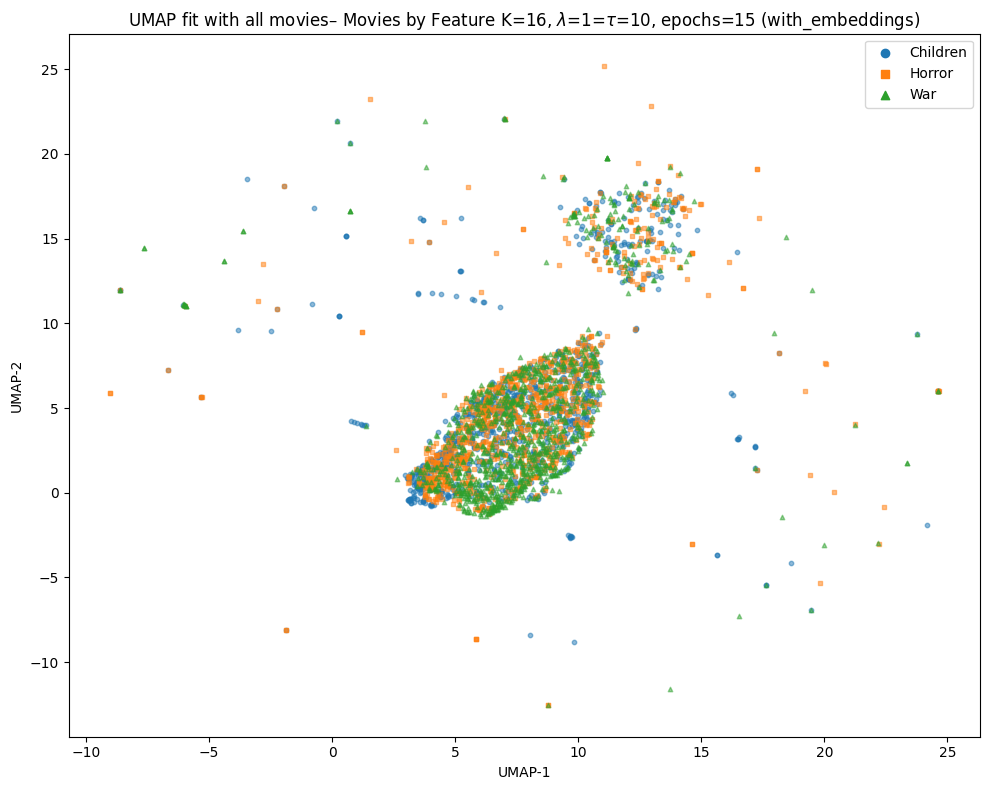

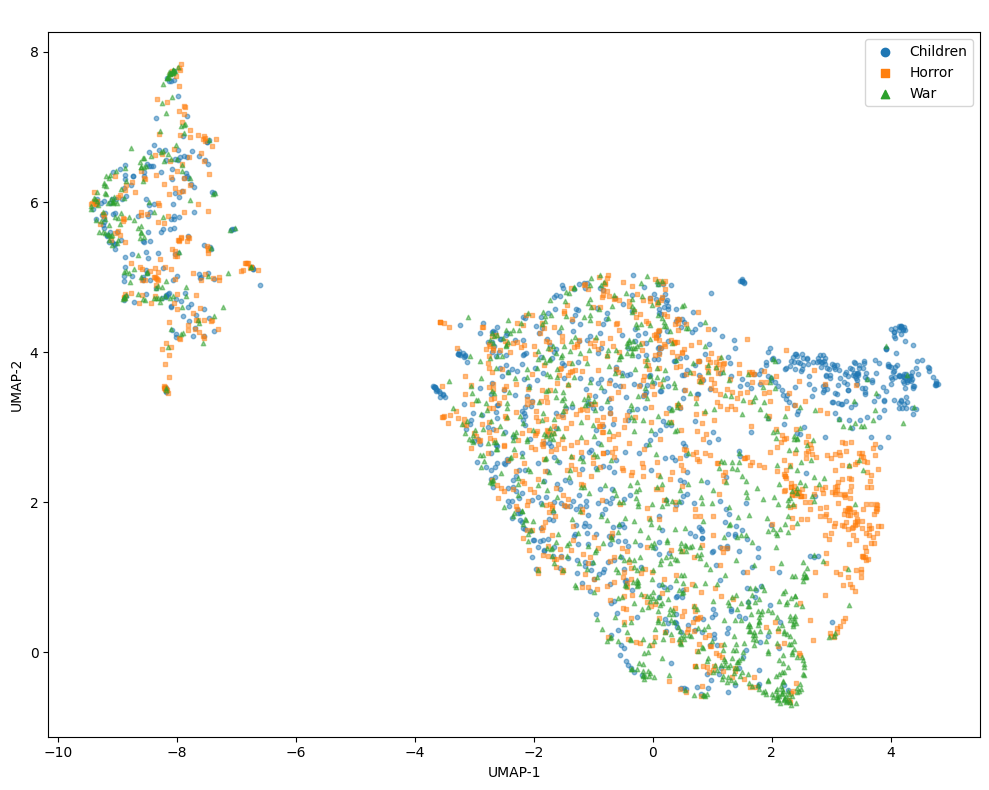

In [248]:
show_labels = False
s = 10

plot_folder = PLOT_FOLDER / '_'.join(feature_ids)
K = fitted_model.get('K')
nepochs = fitted_model.get('nepochs')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')

filename = f"umap-fitted_all_points-plot_movie_embeddings_by_feature-model-K{K}-{mode}.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

title=rf"UMAP fit with all movies– Movies by Feature K={K:02d}, $\lambda$={precision}=$\tau$={vector_penality}, epochs={nepochs} ({mode})"
x_label="UMAP-1"
y_label="UMAP-2"

# title = " "

items_umap_subset = reducer_all_points.transform(item_vectors_subset)
fig, ax = plot_2dvectors(
    embedding=items_umap_subset,
    cluster_labels=feature_assignments,
    cluster_ids=feature_ids,
    point_ids=movie_ids_subset,
    labels=get_movie_title_from_id(
        movie_ids_subset,
        movie_id_to_idx,
        data_movies_title
    ),
    show_labels=show_labels,
    label_fontsize=7,
    cluster_label_fontsize=12,
    s=s,
    alpha=0.5,
    title=title,
    x_label=x_label,
    y_label=y_label
)

save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

filename = f"umap-fitted_subsets-plot_movie_embeddings_by_feature-model-K{K}-{mode}.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

title=rf"UMAP – Movies by Feature K={K:02d}, $\lambda$={precision}=$\tau$={vector_penality}, epochs={nepochs} ({mode})"
x_label="UMAP-1"
y_label="UMAP-2"

title = " "

items_umap_subset = reducer_subsets.transform(item_vectors_subset)
fig, ax = plot_2dvectors(
    embedding=items_umap_subset,
    cluster_labels=feature_assignments,
    cluster_ids=feature_ids,
    point_ids=movie_ids_subset,
    labels=get_movie_title_from_id(
        movie_ids_subset,
        movie_id_to_idx,
        data_movies_title
    ),
    show_labels=show_labels,
    label_fontsize=7,
    cluster_label_fontsize=12,
    s=s,
    alpha=0.5,
    title=title,
    x_label=x_label,
    y_label=y_label
)

save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

# Plot embeddings K>2: Model trained with features

### Load Model

In [266]:
K_list = [16]
vector_penality= 1
mode_dict = {
    0: "bias_only",
    1: "with_embeddings",
    2: "with_features"
}
mode = mode_dict[2]
models_folder =  Path(REMOTE_MODEL_FOLDER) / mode
pattern = "latest.joblib$"
models =  load_models_filtered(models_folder, K_list= K_list,vector_penality_list = [vector_penality],  pattern=pattern)

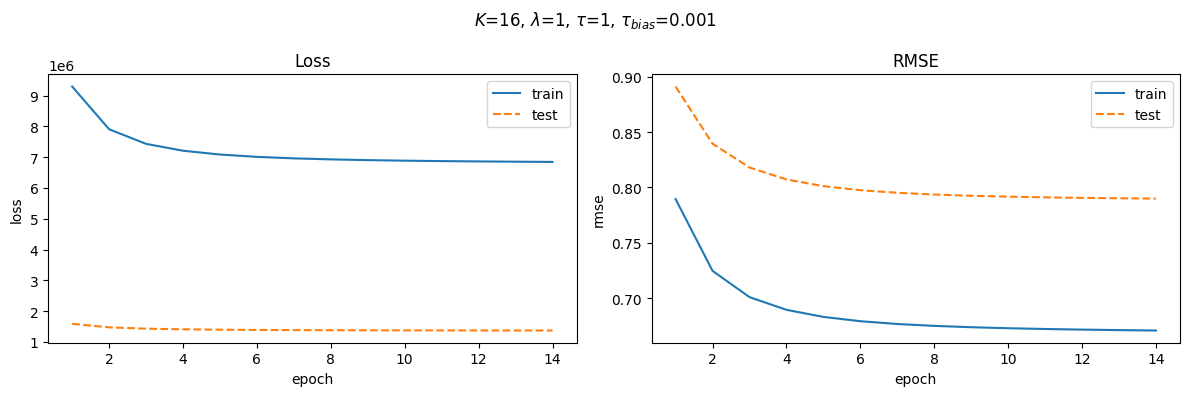

In [267]:
plot_als_curves_multiple_models(models)

In [268]:
fitted_model = models[-1]

## Polarizing Movies

In [269]:
item_vectors = fitted_model.get('item_vectors')

atleast_nratings = 100
nratings_by_item = fitted_model.get('nratings_by_item')
mask = nratings_by_item >= atleast_nratings
indices_atleast_nratings = np.arange(len(mask))[mask]

In [270]:
items_vectors_norm, _ = get_top_long_trait_vector(
    item_vectors,
    sort_flag=False,
    topn=None
)
items_vectors_norms_atleast_nratings = items_vectors_norm[indices_atleast_nratings]
lower_outliers, indices_lower, upper_outliers, indices_upper = get_outliers_iqr(items_vectors_norms_atleast_nratings)
indices_atleast_nratings_upper = indices_atleast_nratings[indices_upper]

### Most Plolarizing Movies

In [271]:
long_trait_vector, sort_indices = sort_array(upper_outliers)
long_trait_vector_indices = indices_atleast_nratings_upper[sort_indices]
long_trait_vector_ids = get_id_from_idx(long_trait_vector_indices, movie_idx_to_id)
bins, counts_for_each_items = get_rating_distribution_for_items(
    ratings_by_movie_csr,
    long_trait_vector_ids,
    movie_id_to_idx,
    bin_width=0.5
)
_, long_trait_vector_ratings =  get_rows_from_csr(ratings_by_movie_csr, list(long_trait_vector_indices))
print(f"There are {len(long_trait_vector_ratings)} polarizing movies")

There are 272 polarizing movies


[array([3. , 5. , 2. , 4. , 5. , 4. , 1. , 0.5, 1. , 1. , 4. , 2. , 2. ,
        1. , 5. , 3.5, 1. , 4. , 1. , 2.5, 4. , 4. , 3. , 3. , 4. , 1. ,
        1. , 1. , 5. , 5. , 4. , 3.5, 3.5, 4. , 2. , 2. , 0.5, 3. , 3. ,
        3. , 4. , 4. , 1. , 3. , 4. , 1. , 2. , 4. , 0.5, 1. , 4. , 1. ,
        1. , 3. , 5. , 3. , 1. , 3. , 5. , 5. , 1. , 1. , 3. , 3. , 2. ,
        2. , 3. , 4. , 3. , 2. , 0.5, 1. , 1. , 3.5, 5. , 2. , 3.5, 3. ,
        2. , 1. , 0.5, 5. , 2. , 1. , 1. , 3. , 1. , 1. , 1. , 2. , 4. ,
        2. , 4. , 3.5, 2. , 3. , 3. , 3. , 1. , 3. , 1. , 4. , 1. , 3. ,
        1. , 2. , 3. , 4. , 4. , 3. , 4. , 5. , 2. , 4.5, 5. , 3.5, 4. ,
        4. , 2. , 1.5, 1. , 3. , 1. , 3. , 5. , 3. , 4. , 5. , 2. , 4. ,
        4. , 4. , 1. , 4.5, 5. , 4. , 1. , 4. , 2. , 0.5, 3. , 2. , 4. ,
        3. , 1. , 2. , 4. , 4. , 4. , 3. , 3. , 4. , 4. , 2. , 5. , 1. ,
        2. , 4. , 1. , 3.5, 3. , 2. , 1. , 0.5, 4. , 1. , 3. , 5. , 1. ,
        3. , 5. , 3.5, 3. , 4. , 2.5, 2.5, 2. , 5. 

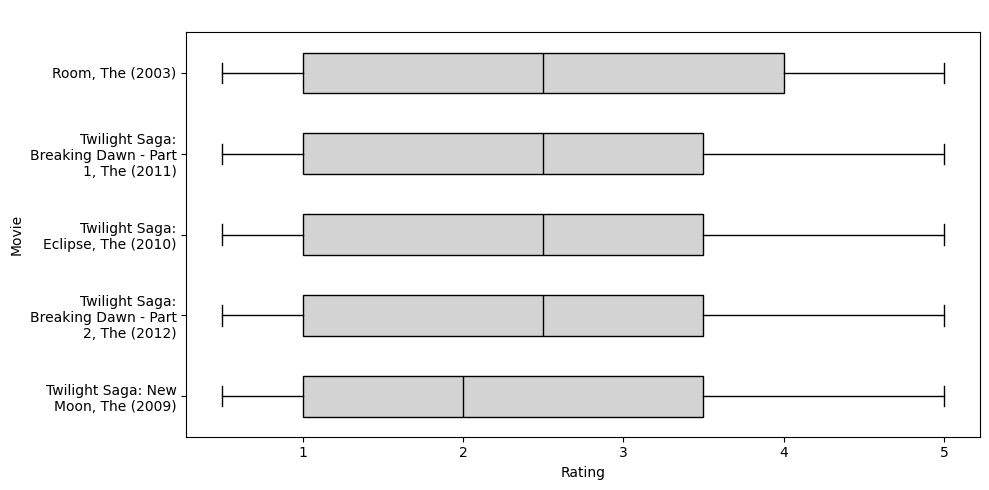

In [255]:
topn = 5
long_traits_titles = get_movie_title_from_id(long_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)

plot_folder = PLOT_FOLDER
filename = f"plot_top-long-trait-boxplot-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if long_trait_vector_ratings:

    title = "Top Movie with Long Traits vectors box-plot Rating Distribution"
    title = " "
    fig, ax = plot_multiple_box_general(
        x_labels=long_traits_titles,
        y_values=long_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Movie",
        ylabel="Rating",
        title=title,
        horizontal=True,
        rotate_xticks=30,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

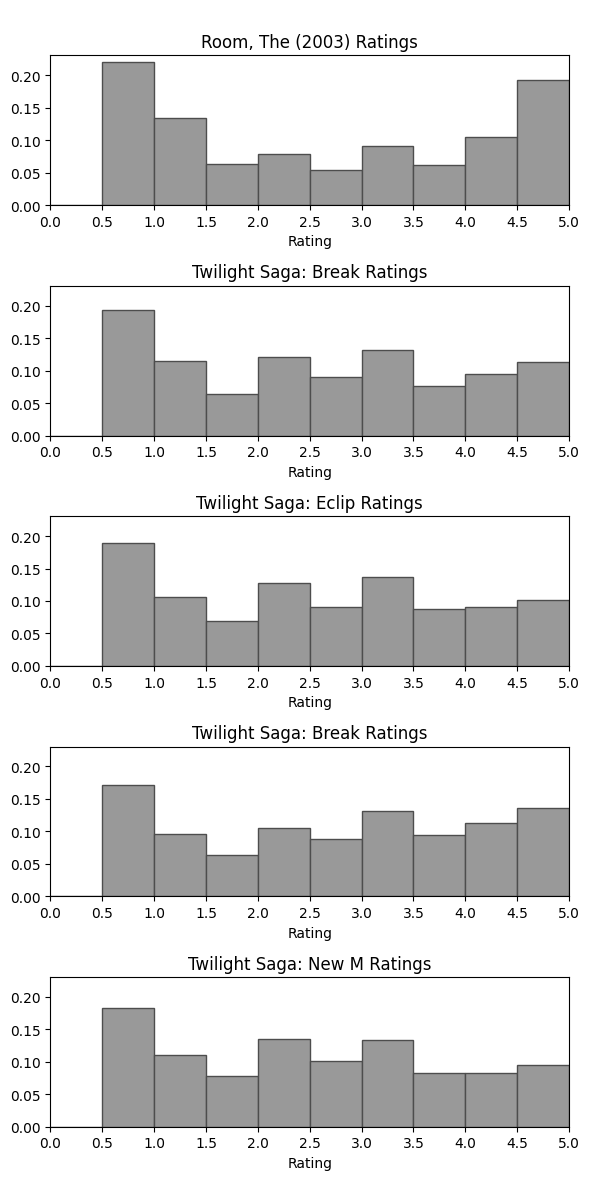

In [256]:
topn = 5
long_traits_titles = get_movie_title_from_id(long_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)
plot_folder = PLOT_FOLDER

K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_top-short-trait-rating-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if long_trait_vector_ratings:
    title = "Top Movie with Short Traits vectors Rating Distribution"
    title = " "

    plot_distribution_general(
        x_labels=long_traits_titles,
        y_values=long_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Rating",
        ylabel="Density",
        title=title,
        horizontal=False,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

### Least Plolarizing Movies

In [257]:
indices_atleast_nratings_upper = indices_atleast_nratings[indices_lower]
short_trait_vector, sort_indices = sort_array(lower_outliers, descending=False)
short_trait_vector_indices = indices_atleast_nratings_upper[sort_indices]
short_trait_vector_ids = get_id_from_idx(short_trait_vector_indices, movie_idx_to_id)

bins, counts_for_each_items = get_rating_distribution_for_items(
    ratings_by_movie_csr,
    short_trait_vector_ids,
    movie_id_to_idx,
    bin_width=0.5
)
_, short_trait_vector_ratings =  get_rows_from_csr(ratings_by_movie_csr, list(short_trait_vector_indices))

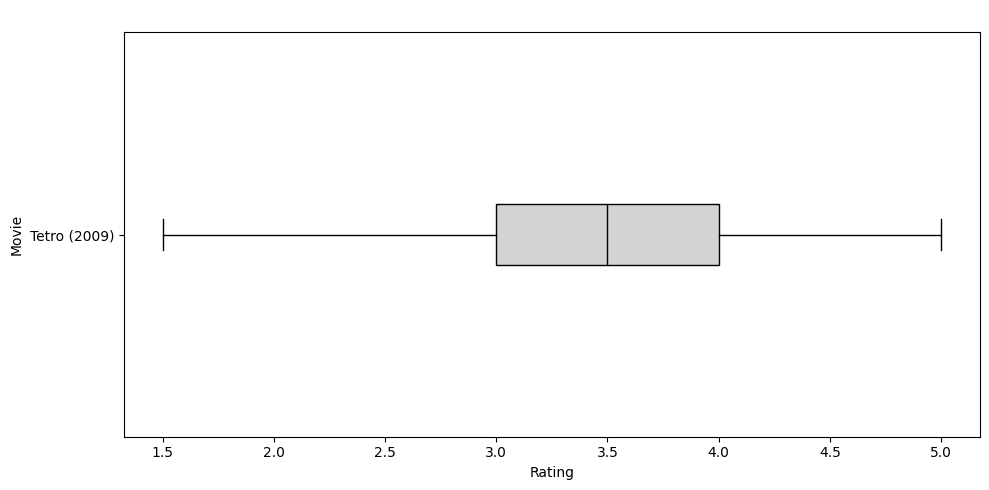

In [258]:
topn = 5
short_traits_titles = get_movie_title_from_id(short_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)

plot_folder = PLOT_FOLDER
filename = f"plot_top-short-trait-boxplot-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if short_trait_vector_ratings:

    title = "Top Movie with short Traits vectors box-plot Rating Distribution"
    title = " "
    fig, ax = plot_multiple_box_general(
        x_labels=short_traits_titles,
        y_values=short_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Movie",
        ylabel="Rating",
        title=title,
        horizontal=True,
        rotate_xticks=30,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

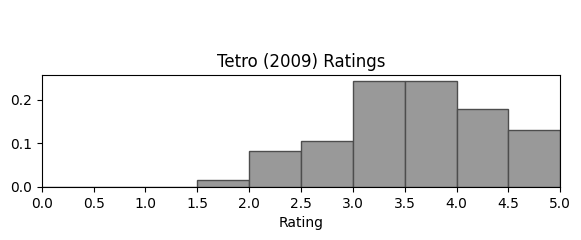

In [259]:
topn = 5
short_traits_titles = get_movie_title_from_id(short_trait_vector_ids,
                                             movie_id_to_idx,
                                             movies_title)
plot_folder = PLOT_FOLDER

K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"plot_top-short-trait-rating-distribution.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

if short_trait_vector_ratings:
    title = "Top Movie with Short Traits vectors Rating Distribution"
    title = " "

    plot_distribution_general(
        x_labels=short_traits_titles,
        y_values=short_trait_vector_ratings,
        sort=False,
        topn=topn,
        sort_stat="median",
        bw_plot=True,
        xlabel="Rating",
        ylabel="Density",
        title=title,
        horizontal=False,
    )

    save_plot(
        plot_filepath,
        fig=None,
        formats="pdf",
        timestamps=False,
        use_tex=False,
        dpi=300,
        overwrite=True
    )
else:
    !rm -rf "{plot_filepath}"

## Movies

In [260]:
item_vectors = fitted_model.get('item_vectors')
feature_vectors = fitted_model.get('feature_vectors')
feature_vectors_subset = feature_vectors[get_indices(feature_ids, fitted_model.get('features_ids'))]
sample_size_each = 10**3
(
    item_vectors_subset,
    movie_ids_subset,
    feature_assignments
) = get_movies_by_features(
        feature_ids,
        feature_id_to_idx,
        movies_by_feature_csr,
        item_vectors,
        movie_idx_to_id,
        feature_vectors_subset,
        mode="xor",
        sample_size_each=sample_size_each)


In [261]:
reducer_all_points = compute_umap_reducer(item_vectors, n_components=2)
reducer_subsets = compute_umap_reducer(item_vectors_subset, n_components=2)

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.12/dist-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/usr/local/lib/python3.12/dist-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


['/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/embeddings_and_polarization/Children_Horror_War/umap-fitted_subsets-plot_movie_embeddings_by_feature-model-K16-with_features-K16-best_nepochs14-maxiter50-lambda1-tau1-with_features.pdf']

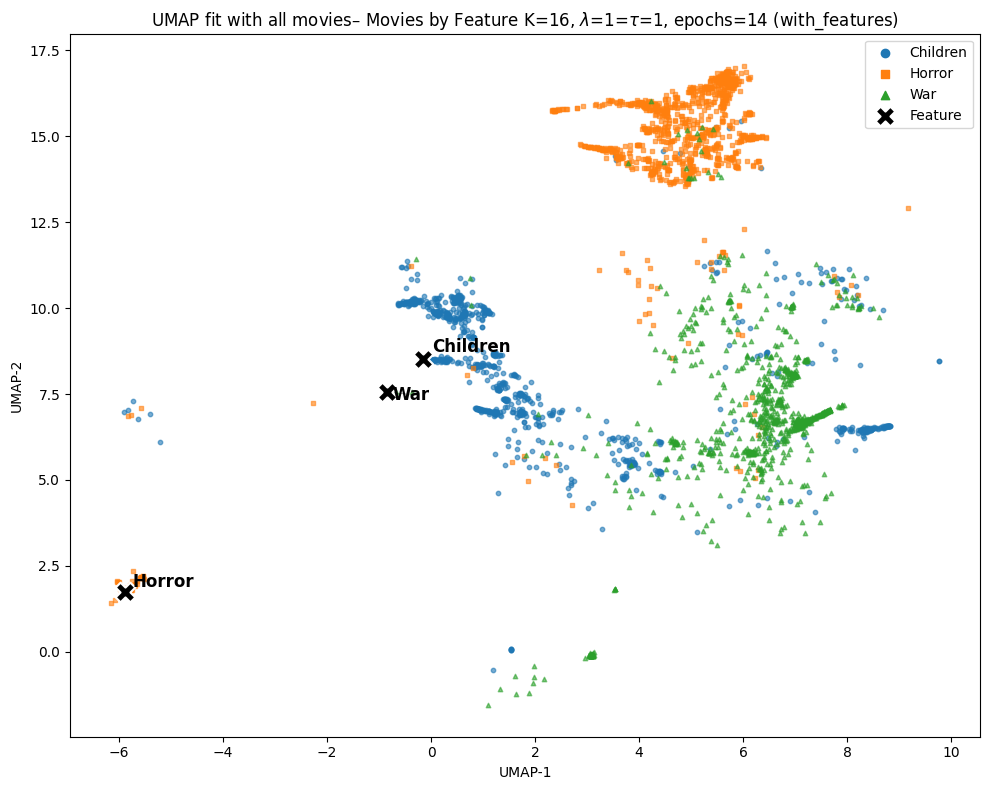

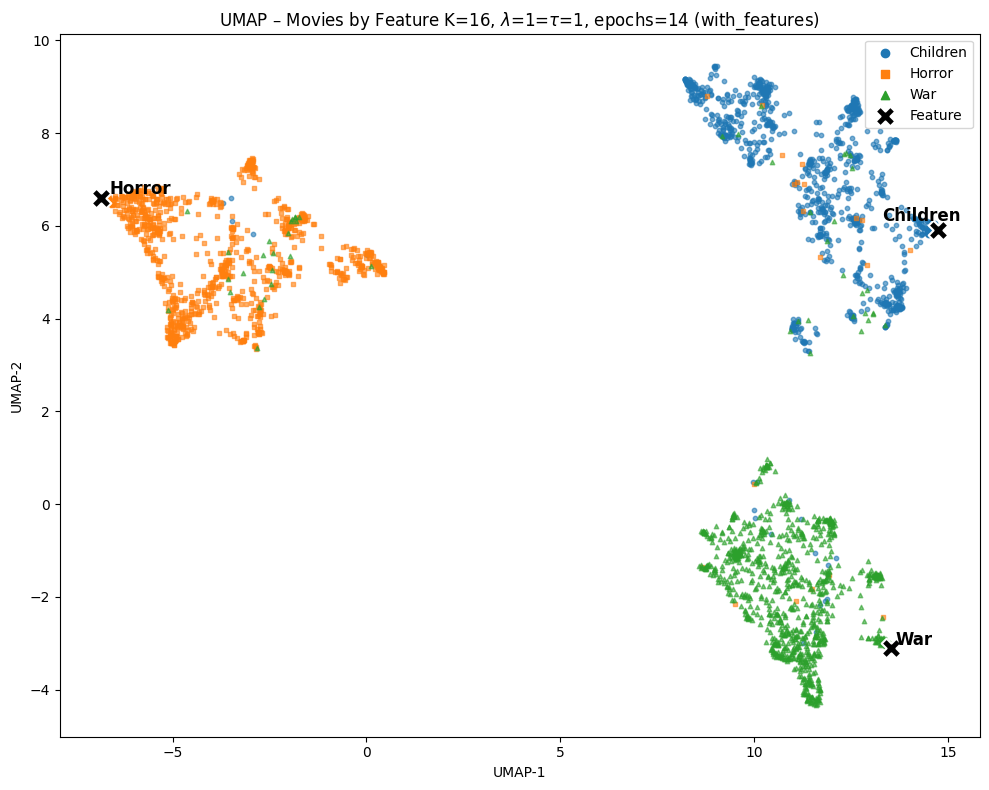

In [262]:
show_labels = False
plot_feature_embeddings = True
s = 10


plot_folder = PLOT_FOLDER / '_'.join(feature_ids)
K = fitted_model.get('K')
nepochs = fitted_model.get('nepochs')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')

filename = f"umap-fitted_all_points-plot_movie_embeddings_by_feature-model-K{K}-{mode}.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

title=rf"UMAP fit with all movies– Movies by Feature K={K:02d}, $\lambda$={precision}=$\tau$={vector_penality}, epochs={nepochs} ({mode})"
x_label="UMAP-1"
y_label="UMAP-2"

# title = " "

items_umap_subset = reducer_all_points.transform(item_vectors_subset)
feature_vectors_umap_subset = reducer_all_points.transform(feature_vectors_subset)
fig, ax = plot_2dvectors(
    embedding=items_umap_subset,
    cluster_labels=feature_assignments,
    cluster_ids=feature_ids,
    point_ids=movie_ids_subset,
    labels=get_movie_title_from_id(
        movie_ids_subset,
        movie_id_to_idx,
        data_movies_title
    ),
    cluster_embeddings=feature_vectors_umap_subset,
    plot_cluster_embeddings=plot_feature_embeddings,
    show_labels=show_labels,
    label_fontsize=7,
    cluster_label_fontsize=12,
    s=s,
    alpha=0.6,
    title=title,
    x_label=x_label,
    y_label=y_label
)


save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

filename = f"umap-fitted_subsets-plot_movie_embeddings_by_feature-model-K{K}-{mode}.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

title=rf"UMAP – Movies by Feature K={K:02d}, $\lambda$={precision}=$\tau$={vector_penality}, epochs={nepochs} ({mode})"
x_label="UMAP-1"
y_label="UMAP-2"

# title = " "

items_umap_subset = reducer_subsets.transform(item_vectors_subset)
feature_vectors_umap_subset = reducer_subsets.transform(feature_vectors_subset)
fig, ax = plot_2dvectors(
    embedding=items_umap_subset,
    cluster_labels=feature_assignments,
    cluster_ids=feature_ids,
    point_ids=movie_ids_subset,
    labels=get_movie_title_from_id(
        movie_ids_subset,
        movie_id_to_idx,
        data_movies_title
    ),
    cluster_embeddings=feature_vectors_umap_subset,
    plot_cluster_embeddings=plot_feature_embeddings,
    show_labels=show_labels,
    label_fontsize=7,
    cluster_label_fontsize=12,
    s=s,
    alpha=0.6,
    title=title,
    x_label=x_label,
    y_label=y_label
)

save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

## Features

In [263]:
feature_vectors = fitted_model['feature_vectors']
reducer_feature = compute_umap_reducer(feature_vectors, n_components=2)
all_features_umap = reducer_feature.embedding_

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


['/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/embeddings_and_polarization/umap-plot_feature_embeddings_by_feature-K16-best_nepochs14-maxiter50-lambda1-tau1-with_features.pdf']

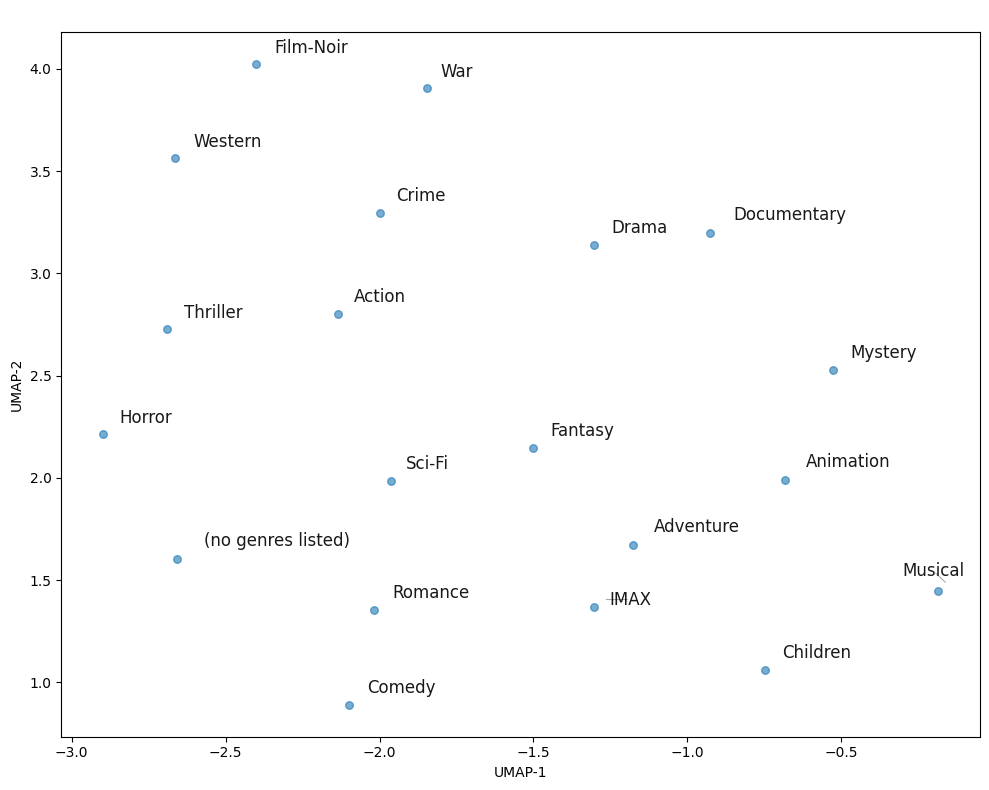

In [264]:
plot_folder = PLOT_FOLDER
K = fitted_model.get('K')
max_iter = fitted_model.get('max_iter')
precision = fitted_model.get('precision')
vector_penality = fitted_model.get('vector_penality')
mode = fitted_model.get('mode')
filename = f"umap-plot_feature_embeddings_by_feature.pdf"
filename = add_suffix_model_info(filename, fitted_model)
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

title=rf"UMAP – Features K={K:02d}, $\lambda$={precision}=$\tau$={vector_penality}, iter={max_iter} ({mode})"
x_label="UMAP-1"
y_label="UMAP-2"

title = " "

fig, ax = plot_2dvectors(
    embedding=all_features_umap,
    cluster_labels=None,
    point_ids=fitted_model['features_ids'],
    show_labels=True,
    label_fontsize=12,
    label_alpha=0.9,
    title=title,
    x_label=x_label,
    y_label=y_label
)

save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)